# Customer Churn Analysis

This notebook explores the included Telco dataset and compares Logistic Regression with Random Forest using the same preprocessing and stratified test split. Run it from the project root or this notebook's `notebooks` folder.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style='whitegrid', palette='crest')
candidates = [Path('data/customer_churn.csv'), Path('../data/customer_churn.csv')]
data_path = next((path for path in candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('Place customer_churn.csv in the project data/ folder; see README.md.')
data = pd.read_csv(data_path)
data.columns = data.columns.str.strip()
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
print(f'Shape: {data.shape[0]} rows x {data.shape[1]} columns')

Shape: 7043 rows x 21 columns


In [4]:
display(data.dtypes.rename('dtype').to_frame())
display(data.isna().sum().rename('missing values').to_frame())
print('Duplicate rows:', data.duplicated().sum())
display(data.describe(include='all').T)

,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,missing values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
data = data.drop_duplicates().copy()
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
target = data['Churn'].astype('string').str.strip().map({'Yes': 1, 'No': 0})
valid = target.notna()
features = data.loc[valid].drop(columns=['customerID', 'Churn'])
target = target.loc[valid].astype(int)
print('Feature rows:', len(features), '| Churn rate:', f'{target.mean():.1%}')

Feature rows: 7043 | Churn rate: 26.5%


## Exploratory Data Analysis

The plots show associations in this sample. They are descriptive and do not establish causality.

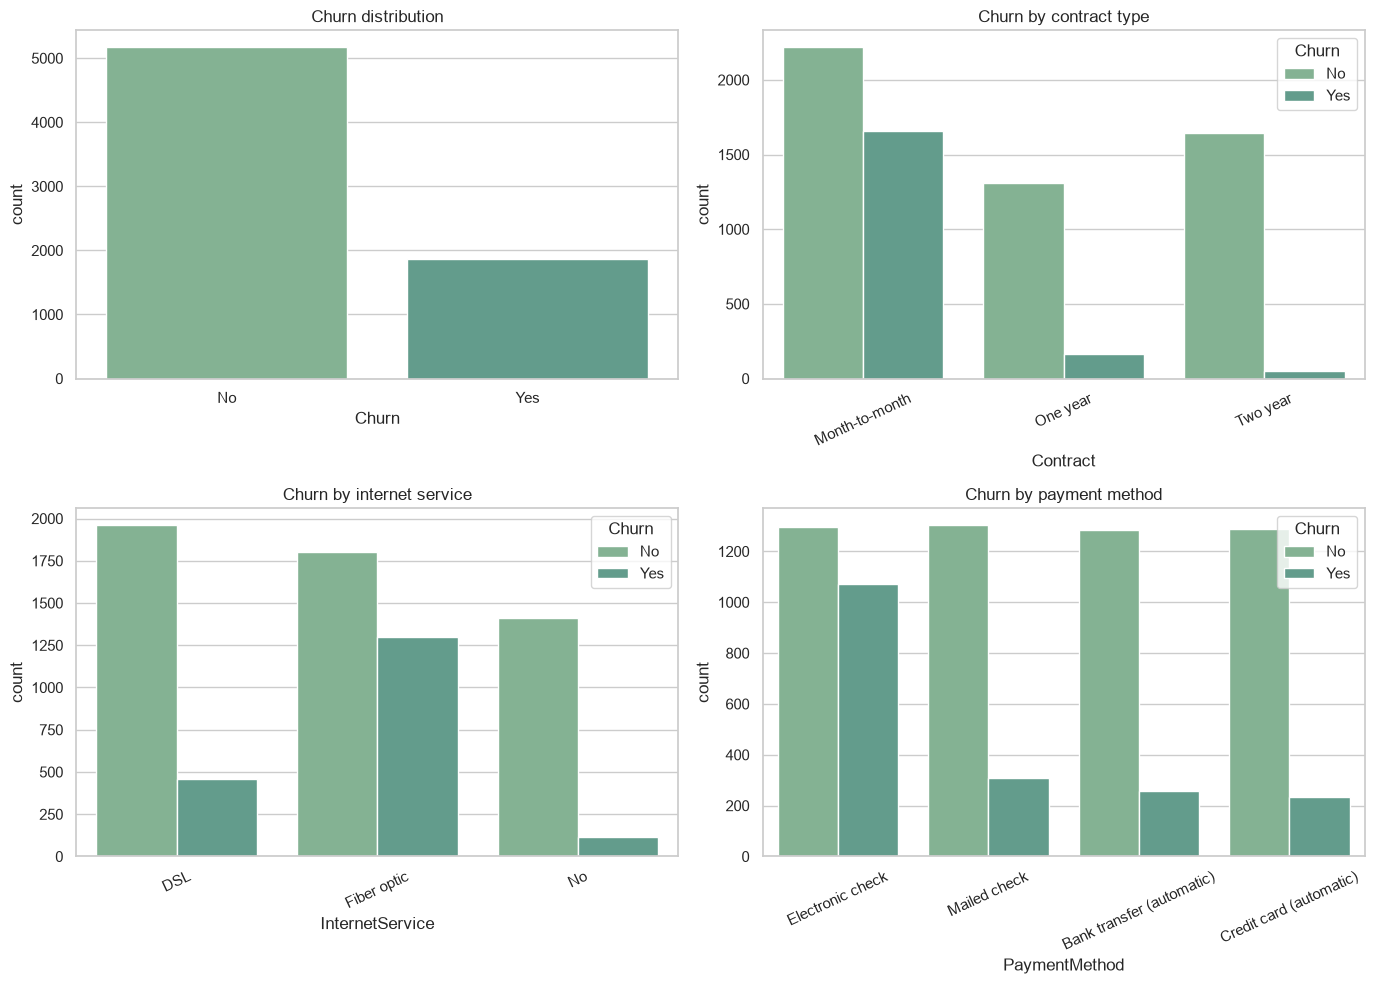

In [6]:
plot_data = features.copy()
plot_data['Churn'] = target.map({1: 'Yes', 0: 'No'})
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=plot_data, x='Churn', hue='Churn', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Churn distribution')
for axis, column, title in [(axes[0, 1], 'Contract', 'Churn by contract type'), (axes[1, 0], 'InternetService', 'Churn by internet service'), (axes[1, 1], 'PaymentMethod', 'Churn by payment method')]:
    sns.countplot(data=plot_data, x=column, hue='Churn', ax=axis)
    axis.set_title(title)
    axis.tick_params(axis='x', rotation=25)
    axis.legend(title='Churn')
plt.tight_layout()
plt.show()

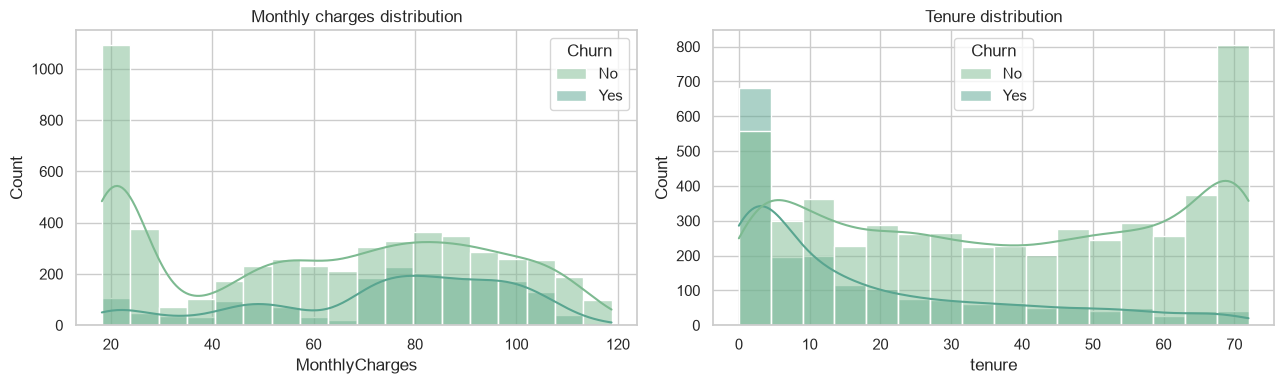

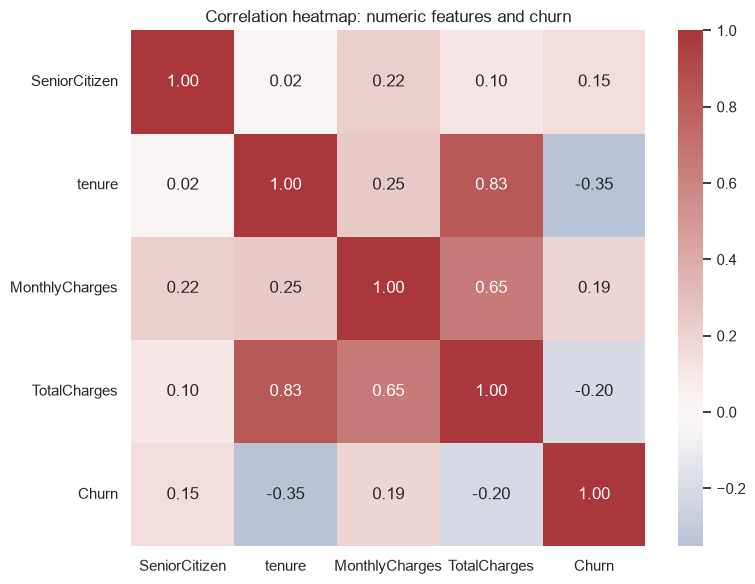

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=plot_data, x='MonthlyCharges', hue='Churn', kde=True, ax=axes[0])
axes[0].set_title('Monthly charges distribution')
sns.histplot(data=plot_data, x='tenure', hue='Churn', kde=True, ax=axes[1])
axes[1].set_title('Tenure distribution')
plt.tight_layout()
plt.show()
numeric = features.select_dtypes(include=[np.number]).copy()
numeric['Churn'] = target
plt.figure(figsize=(8, 6))
sns.heatmap(numeric.corr(), annot=True, cmap='vlag', center=0, fmt='.2f')
plt.title('Correlation heatmap: numeric features and churn')
plt.tight_layout()
plt.show()

## Model Comparison

Numeric columns receive median imputation and standard scaling. Categorical columns receive most-frequent imputation and one-hot encoding. The preprocessing is fit only on each training fold via the pipeline.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42, stratify=target)
numeric_columns = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_columns = X_train.select_dtypes(exclude=[np.number]).columns.tolist()
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_columns),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_columns),
])
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}
results = {}
for name, classifier in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', classifier)])
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    probability = pipeline.predict_proba(X_test)[:, 1]
    results[name] = {'pipeline': pipeline, 'predictions': predicted, 'probabilities': probability, 'Accuracy': accuracy_score(y_test, predicted), 'Precision': precision_score(y_test, predicted, zero_division=0), 'Recall': recall_score(y_test, predicted, zero_division=0), 'F1': f1_score(y_test, predicted, zero_division=0), 'ROC-AUC': roc_auc_score(y_test, probability)}
comparison = pd.DataFrame({name: {metric: value for metric, value in result.items() if metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']} for name, result in results.items()}).T
display(comparison.style.format('{:.4f}'))
best_name = max(results, key=lambda name: (results[name]['ROC-AUC'], results[name]['F1']))
print('Selected model by ROC-AUC, then F1:', best_name)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
Random Forest,0.7757,0.6000,0.4652,0.5241,0.8186


Selected model by ROC-AUC, then F1: Logistic Regression


              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



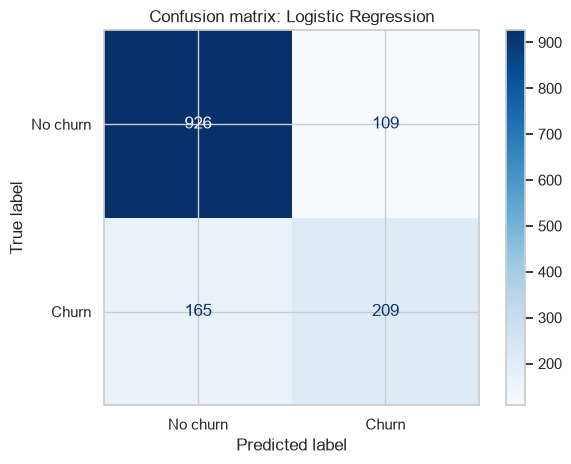

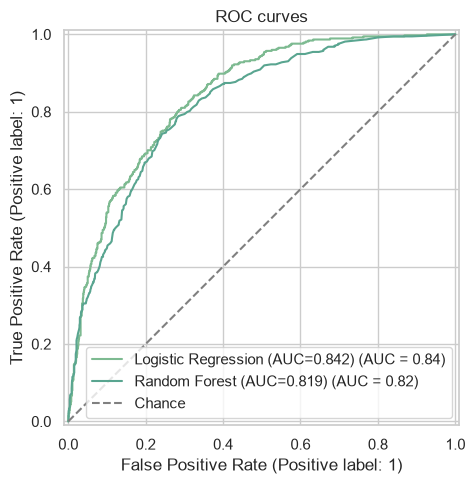

In [9]:
best_result = results[best_name]
print(classification_report(y_test, best_result['predictions'], target_names=['No churn', 'Churn'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_result['predictions'], display_labels=['No churn', 'Churn'], cmap='Blues')
plt.title(f'Confusion matrix: {best_name}')
plt.tight_layout()
plt.show()
fig, axis = plt.subplots(figsize=(7, 5))
for name, result in results.items():
    RocCurveDisplay.from_predictions(y_test, result['probabilities'], name=f"{name} (AUC={result['ROC-AUC']:.3f})", ax=axis)
axis.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Chance')
axis.legend(loc='lower right')
axis.set_title('ROC curves')
plt.tight_layout()
plt.show()